# **EDA Notebook**



---
## 0. Setup Environment

In [1]:
# DO NOT MODIFY THE CODE IN THIS CELL
!pip install -q utstd

from utstd.folders import *
from utstd.ipyrenders import *

at = AtFolder(
    course_code=36106,
    assignment="AT3",
)
at.run()

import warnings
warnings.simplefilter(action='ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 65.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.42 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
Mounted at /content/gdrive

You can now save your data files in: /content/gdrive/MyDrive/36106/assignment/AT3/data


---
## Student Information

In [2]:
group_name = "Group 21"
student_name = "Vishwesh Kalyam"
student_id = "25424211"


In [3]:
# Do not modify this code
print_tile(size="h1", key='group_name', value=group_name)

In [4]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

### 0.a Install Additional Packages

> If you are using additional packages, you need to install them here using the command: `! pip install <package_name>`

In [6]:
! pip install matplotlib seaborn -q


### 0.b Import Packages

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


---
## B. Data Understanding

In [8]:
# Do not modify this code
try:
  df = pd.read_csv(at.folder_path / "unit_measure.csv")
except Exception as e:
  print(e)

### B.1 Explore Dataset

In [9]:
print(f"Shape: {df.shape}")
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
df.head(10)


Shape: (38, 2)

Data types:
unit_measure_code    object
name                 object
dtype: object

Missing values:
unit_measure_code    0
name                 0
dtype: int64


,unit_measure_code,name
0,ee0468c7-6417-489a-b233-da57ab966174,Boxes
1,7768b253-7430-402f-b90f-1e025c57459b,Bottle
2,1f485b4e-fc4d-47b2-ab57-af19b21eee40,Celsius
3,e87c6cb9-24ca-405a-996c-8f59ab7730fa,Canister
4,91fa7aa6-72aa-40a6-822f-8b80aa9f6376,Carton
5,1f5f8ee7-58c4-4c4e-b8db-b7c1025b3400,Cubic meters
6,b4c6422a-e170-4911-852f-38a7c19f5573,Cubic centimeter
7,5c3d2f68-8573-4e53-8c4e-a72a5f92518e,Cubic decimeter
8,e2e52698-ce31-4fb2-866f-bcffbdfd3147,Centimeter
9,7d2f574f-2c4b-45e5-bb2e-7c74c247492c,Square centimeter


In [10]:
dataset_insights = """
The unit_measure dataset is a small reference table with just 38 rows and 2 columns - unit_measure_code and name - both fully populated with no missing values or duplicates. It serves purely as a lookup table mapping UUID identifiers to human-readable unit names such as Kilogram, Inch, and Liter, and is likely used as a foreign key reference in the product table for weight and size measurements rather than as a direct analytical dataset.
"""


In [11]:
# Do not modify this code
print_tile(size="h3", key='dataset_insights', value=dataset_insights)

---
## B.2 Explore Feature of Interest unit categories

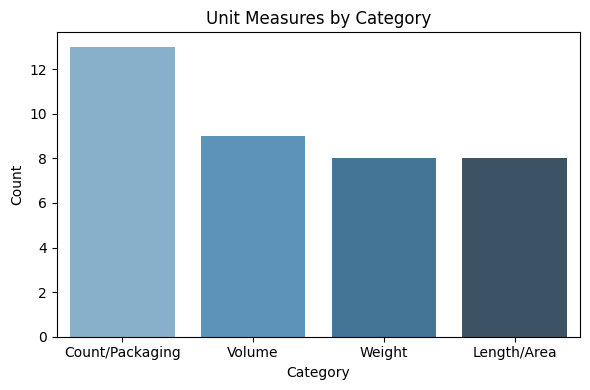

category
Count/Packaging    13
Volume              9
Weight              8
Length/Area         8
Name: count, dtype: int64


In [12]:
def categorise(name):
    name = name.lower()
    if any(w in name for w in ["gram", "kilogram", "pound", "ounce", "ton", "milligram"]):
        return "Weight"
    elif any(w in name for w in ["liter", "gallon", "pint", "milliliter", "cubic"]):
        return "Volume"
    elif any(w in name for w in ["meter", "inch", "foot", "centimeter", "millimeter", "kilometer", "decimeter"]):
        return "Length/Area"
    else:
        return "Count/Packaging"

df["category"] = df["name"].apply(categorise)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="category", palette="Blues_d", order=df["category"].value_counts().index)
plt.title("Unit Measures by Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(df["category"].value_counts())


In [13]:
feature_1_insights = """
Grouping the 38 unit names into broader categories reveals that the table covers a fairly diverse set of measurement types - length/area units are the most represented, followed by volume and weight, while count and packaging units (Each, Dozen, Pack etc.) make up the remainder, reflecting the variety of physical product attributes tracked across the catalogue.
"""


In [14]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

---
## B.3 Explore Feature of Interest `unit_measure_code`

In [15]:
print("Total rows:", len(df))
print("Unique codes:", df["unit_measure_code"].nunique())
print("Duplicate codes:", df["unit_measure_code"].duplicated().sum())


Total rows: 38
Unique codes: 38
Duplicate codes: 0


In [16]:
feature_2_insights = """
All 38 unit_measure_code values are unique UUID strings with no duplicates, confirming the table is a clean reference dataset where each row represents a distinct unit of measurement that can be reliably used as a foreign key in joins with other tables like product.
"""


In [17]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

---
## B.4 Explore Feature of Interest

In [18]:
print("No further features to explore - this is a 2-column reference table with limited standalone analytical value.")


No further features to explore - this is a 2-column reference table with limited standalone analytical value.


In [19]:
feature_n_insights = """
With only two columns and 38 rows, the unit_measure table has no further features worth exploring in itself per say - its value lies entirely in enriching other tables through joins in the data preparation stage.
"""


In [20]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)